# Template Matching, Hough Transforms and Corner Detection

Three classic ways to find known structures: template matching slides a small reference image over a scene; the Hough transform votes for lines and circles in edge space; corner detectors find stable points where intensity changes in two directions. Together they cover most pre-deep-learning detection tasks.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Template matching with matchTemplate

`cv2.matchTemplate` slides the template over the image and scores every position. With `TM_CCOEFF_NORMED` scores are in -1..1 and the best position comes from `cv2.minMaxLoc`. It finds exact appearances - it does not handle scale or rotation changes.

Best match score: 1.0 at (200, 100)


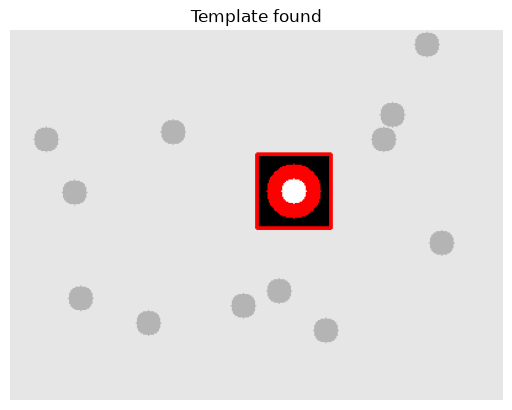

In [2]:
scene = cv2.imread("../assets/scene.png")
template = cv2.imread("../assets/template.png")
th, tw = template.shape[:2]
result = cv2.matchTemplate(scene, template, cv2.TM_CCOEFF_NORMED)
_, max_val, _, max_loc = cv2.minMaxLoc(result)
out = scene.copy()
cv2.rectangle(out, max_loc, (max_loc[0] + tw, max_loc[1] + th), (0, 0, 255), 2)
print("Best match score:", round(float(max_val), 3), "at", max_loc)
show(out, "Template found")

## Finding multiple matches

Threshold the result map to get every position above a confidence level, then draw all of them. Nearby duplicate hits are normal - production code adds non-maximum suppression; here a simple minimum-distance filter does the job.

Matches kept after distance filter: 1


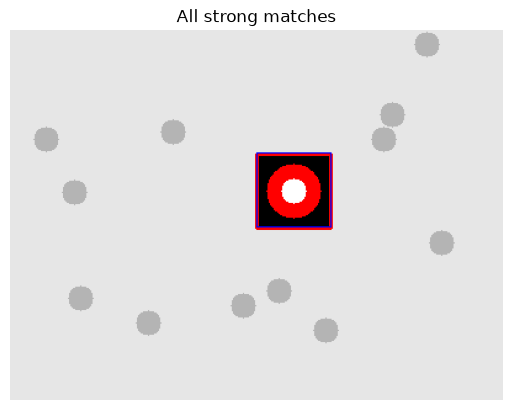

In [3]:
locations = np.where(result >= 0.85)
points = []
for pt in zip(*locations[::-1]):
    if all(abs(pt[0] - q[0]) > 20 or abs(pt[1] - q[1]) > 20 for q in points):
        points.append(pt)
print("Matches kept after distance filter:", len(points))
for pt in points:
    cv2.rectangle(out, pt, (pt[0] + tw, pt[1] + th), (255, 0, 0), 1)
show(out, "All strong matches")

## Hough line transform

Every edge point votes for all lines that could pass through it; lines with enough votes (the threshold) are real lines. `cv2.HoughLinesP` (probabilistic) returns line segments directly and is the practical choice: parameters are rho, theta, vote threshold, minLineLength and maxLineGap.

Line segments found: 12


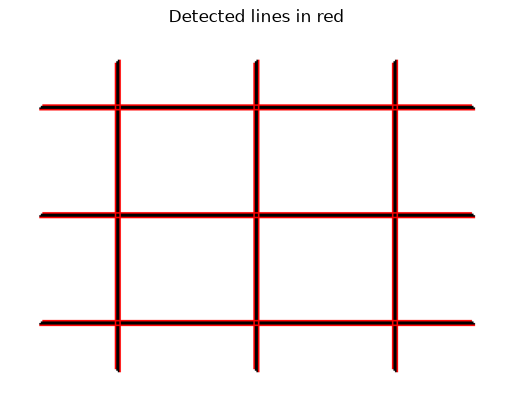

In [4]:
grid = np.full((240, 320, 3), 255, np.uint8)
for y in (50, 120, 190): cv2.line(grid, (20, y), (300, y), (0, 0, 0), 2)
for x in (70, 160, 250): cv2.line(grid, (x, 20), (x, 220), (0, 0, 0), 2)
edges = cv2.Canny(cv2.cvtColor(grid, cv2.COLOR_BGR2GRAY), 50, 150)
lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=80, minLineLength=60, maxLineGap=10)
segments = [] if lines is None else lines.reshape(-1, 4)  # shape differs between OpenCV versions
print("Line segments found:", len(segments))
for l in segments:
    cv2.line(grid, (int(l[0]), int(l[1])), (int(l[2]), int(l[3])), (0, 0, 255), 1)
show(grid, "Detected lines in red")

## Hough circle transform

`cv2.HoughCircles` votes for circle centres and radii. It is sensitive to its parameters: blur first, and tune param2 (the vote threshold) - lower finds more circles including false ones. dp is the resolution ratio of the accumulator.

Circles found: 0 - try lowering param2


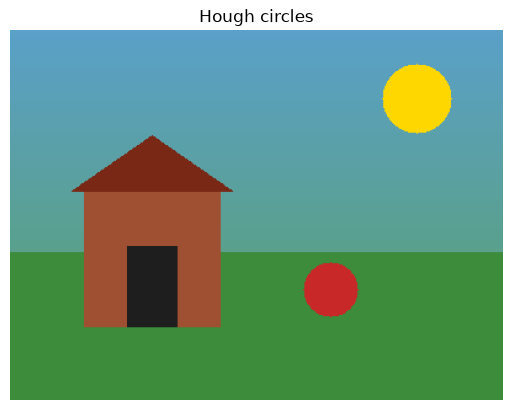

In [5]:
img = cv2.imread("../assets/test_image.png")
gray = cv2.medianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 5)
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=40, param1=120, param2=35, minRadius=10, maxRadius=60)
if circles is not None:
    circles = np.round(circles[0]).astype(int)
    print("Circles found:", len(circles))
    for (x, y, r) in circles:
        cv2.circle(img, (x, y), r, (0, 255, 0), 2)
else:
    print("Circles found: 0 - try lowering param2")
show(img, "Hough circles")

## Harris corner detection

Corners are points where intensity changes strongly in two directions - the most stable landmarks in an image. `cv2.cornerHarris` returns a response map; points above a fraction of the maximum are corners. Results are usually dilated so the points are visible.

Corner response pixels: 1617


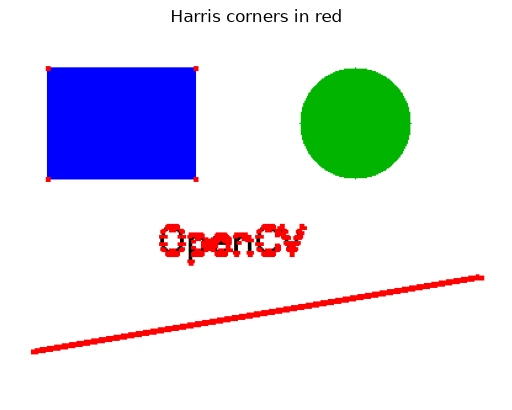

In [6]:
shapes = cv2.imread("../assets/shapes.png")
gray_s = cv2.cvtColor(shapes, cv2.COLOR_BGR2GRAY)
response = cv2.cornerHarris(np.float32(gray_s), blockSize=2, ksize=3, k=0.04)
response = cv2.dilate(response, None)
corner_pixels = int((response > 0.01 * response.max()).sum())
shapes[response > 0.01 * response.max()] = (0, 0, 255)
print("Corner response pixels:", corner_pixels)
show(shapes, "Harris corners in red")

## Shi-Tomasi corners with goodFeaturesToTrack

`cv2.goodFeaturesToTrack` is the refined, production version of corner detection: you ask for at most N corners with a minimum quality and minimum spacing. Its output feeds directly into optical-flow tracking (notebook 16).

Shi-Tomasi corners: 37


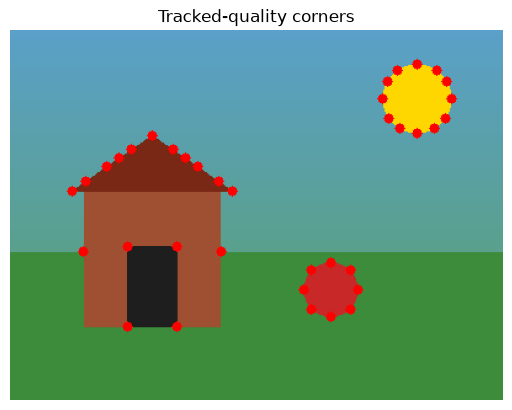

In [7]:
gray_t = cv2.cvtColor(cv2.imread("../assets/test_image.png"), cv2.COLOR_BGR2GRAY)
corners = cv2.goodFeaturesToTrack(gray_t, maxCorners=40, qualityLevel=0.01, minDistance=12)
out = cv2.imread("../assets/test_image.png")
if corners is not None:
    for c in corners.astype(int):
        cv2.circle(out, tuple(c[0]), 4, (0, 0, 255), -1)
    print("Shi-Tomasi corners:", len(corners))
show(out, "Tracked-quality corners")

## Key Points

- matchTemplate finds exact appearances; TM_CCOEFF_NORMED + minMaxLoc is the standard pair.
- Multiple matches need a threshold plus duplicate suppression.
- HoughLinesP returns segments; the vote threshold is the main control.
- HoughCircles needs blur first and careful param2 tuning.
- Harris finds corners from gradient structure; goodFeaturesToTrack is the production version.

## Mini Task

1. Match `template.png` in `scene.png` with TM_SQDIFF_NORMED and note which minMaxLoc value you must use there.
2. Lower the HoughLinesP threshold to 40 and compare the segment count.
3. Detect Shi-Tomasi corners on `shapes.png` with maxCorners=20 and draw them.